# Signal model

Everything in the method notebooks rests on two facts about an FMCW radar: the beat frequency of an echo gives its range, and the phase of the same echo moves by $4\pi/\lambda$ per metre of motion. Range separates a chest from the walls, the phase carries the breathing and the heartbeat.

**One chirp.** The transmitted frequency rises linearly, $f(t) = f_c + S\,t$. An echo from distance $R$ comes back after $\tau = 2R/c$; mixing it with the transmitted chirp leaves, for ADC sample $n$ at rate $f_s$,

$$
s(n) = A\,\exp\!\left(j\,2\pi\,\frac{2SR}{c}\,\frac{n}{f_s} \;+\; j\,\frac{4\pi R}{\lambda}\right).
$$

The first term is a tone at the beat frequency $f_b = 2SR/c$, so an FFT over the samples of one chirp (fast time) turns range into frequency. Two reflectors are resolved when they are at least

$$
\Delta R = \frac{c}{2B}, \qquad B = \frac{S\,N}{f_s}
$$

apart, where $B$ is the part of the sweep that is actually sampled, not the configured ramp. With complex sampling the last unambiguous range is $R_{max} = f_s\,c / (2S)$.

**Many chirps.** The second term does not change within a chirp but changes from frame to frame (slow time) when the chest moves: $R(t) = R_0 + x(t)$ gives a phase $4\pi x(t)/\lambda$. At 60 GHz, $\lambda \approx 5$ mm and 1 mm of chest motion turns the phase by 2.5 rad. Breathing moves the chest wall by several millimetres and wraps the phase more than once per breath; the heartbeat adds 0.1 to 0.5 mm, between 0.25 and 1.3 rad, on top.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=["#1b4965", "#c8553d", "#5c946e", "#8c6d9f"])})
from radar import cube, simulate, vitals
from radar.cube import RadarConfig

The chirp settings decide the range axis. Two examples: the configuration of the simulated scene used for the figures in this folder, and a high-resolution 60 GHz setting with close to 4 GHz of sampled sweep, the regime of our multi-patient recordings.

In [2]:
for name, cfg in [("simulation", RadarConfig(slope=40e12, fs_adc=2e6, n_samples=64, frame_rate=20)),
                  ("high resolution", RadarConfig(slope=60e12, fs_adc=4e6, n_samples=256, frame_rate=20))]:
    print(f"{name:16s} B = {cfg.bandwidth/1e9:4.2f} GHz   range resolution = {100*cfg.range_resolution:4.1f} cm"
          f"   max range = {cfg.max_range:4.1f} m   phase per mm = {cfg.phase_per_mm():.2f} rad")

simulation       B = 1.28 GHz   range resolution = 11.7 cm   max range =  7.5 m   phase per mm = 2.52 rad
high resolution  B = 3.84 GHz   range resolution =  3.9 cm   max range = 10.0 m   phase per mm = 2.52 rad


## The cube and the virtual array

A recording becomes a four-dimensional array: frames $\times$ channels $\times$ chirps $\times$ samples. The IWR6843AOP has 3 transmitters and 4 receivers. With time-division MIMO the transmitters take turns chirp by chirp, and each transmitter-receiver pair behaves like one receiver placed at the sum of their positions. The 12 virtual channels form the layout below (TI `antGeometry0/1`, units of $\lambda/2$); half of them see the echo with inverted sign (`antPhaseRot`) and are corrected before any angle processing (`cube.compensate_aop`).

For an echo from azimuth $\theta$ and elevation $\varphi$, virtual element $m$ at $(p_m, q_m)$ half wavelengths sees

$$
a_m(\theta,\varphi) = \exp\!\big(j\pi\,(p_m \sin\theta\cos\varphi + q_m \sin\varphi)\big).
$$

Along azimuth the array spans four positions, so a delay-and-sum beam is about $2/4$ rad wide at broadside, close to 28° at −3 dB. Two people closer than that, at the same range, fall into one beam. This single number explains most of the multi-person methods in this folder: they either look for a second dimension where people differ (range, breathing rhythm) or use adaptive and subspace methods that go below the beamwidth.

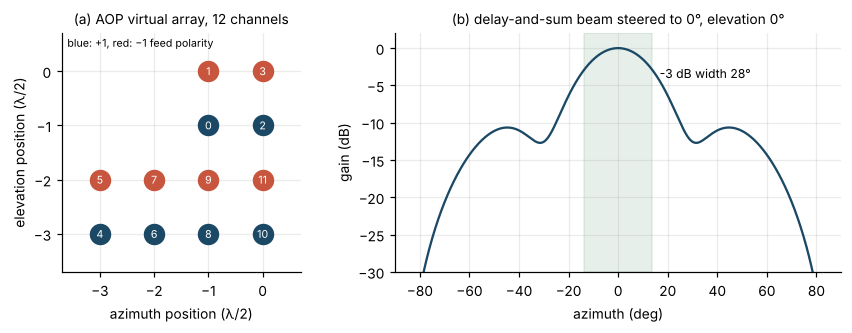

In [3]:
pos = cube.aop_positions()
ang = np.linspace(-90, 90, 721)
from radar.spatial import steering
a0 = steering(pos, 0.0)[:, 0]
pattern = np.abs(steering(pos, ang).conj().T @ a0) / len(a0)

fig, ax = plt.subplots(1, 2, figsize=(8, 3.1), gridspec_kw={"width_ratios": [1, 1.6]})
for m, (p, q) in enumerate(pos):
    ax[0].scatter(p, q, s=170, color="#1b4965" if cube.AOP_ROT[m] > 0 else "#c8553d", zorder=3)
    ax[0].text(p, q, str(m), color="white", ha="center", va="center", fontsize=7, zorder=4)
ax[0].set(xlim=(-3.7, 0.7), ylim=(-3.7, 0.7), xlabel="azimuth position (λ/2)",
          ylabel="elevation position (λ/2)", title="(a) AOP virtual array, 12 channels")
ax[0].set_aspect("equal")
ax[0].text(-3.6, 0.45, "blue: +1, red: −1 feed polarity", fontsize=7)
ax[1].plot(ang, 20 * np.log10(pattern + 1e-6))
half = ang[pattern >= pattern.max() / np.sqrt(2)]
ax[1].axvspan(half.min(), half.max(), color="#5c946e", alpha=0.15)
ax[1].text(half.max() + 3, -4, f"-3 dB width {half.max() - half.min():.0f}°", fontsize=8)
ax[1].set(xlim=(-90, 90), ylim=(-30, 2), xlabel="azimuth (deg)", ylabel="gain (dB)",
          title="(b) delay-and-sum beam steered to 0°, elevation 0°")
plt.tight_layout()

## The simulated scene

The figures in the method notebooks are drawn from a simulated recording (`radar.simulate`), not from measurements, so that every step can be compared with the true chest motion. Results on recorded data are reported in the papers listed in the README.

Three people lie in front of the radar: two at 2.0 m, at −25° and +20°, so that only angle separates them, and one at 2.6 m. Each chest breathes with an inhalation shorter than the exhalation and a slowly varying rate, and carries a heartbeat pulse train with beat-to-beat variability. A bed frame at 1.2 m, a wall at 3.5 m and a static reflection inside the first person's bin stand for the clutter of a ward.

In [4]:
people = [simulate.Person(2.0, -25, rr=14, hr=80),
          simulate.Person(2.0, 20, rr=22, hr=90, amp=0.8),
          simulate.Person(2.6, 5, rr=20, hr=110, amp=0.9)]
clutter = [(1.2, 0, 3.0), (3.5, -40, 2.0), (2.0, -25, 0.6)]
x, truth = simulate.simulate(people, duration=60, clutter=clutter, snr_db=20)
cfg, fs = truth["config"], truth["config"].frame_rate
rp = cube.compensate_aop(cube.range_fft(x))
print("cube (frames, virtual channels, chirps per TX, range bins):", rp.shape)

cube (frames, virtual channels, chirps per TX, range bins): (1200, 12, 2, 64)


The range profile of one frame shows the bed and the wall as the strongest echoes; the chests are weaker and two of them share a bin. In slow time, the phase of the first person's bin follows the chest displacement once the static offset is removed (next notebook), with breathing, its slow rate changes and the heartbeat riding on top.

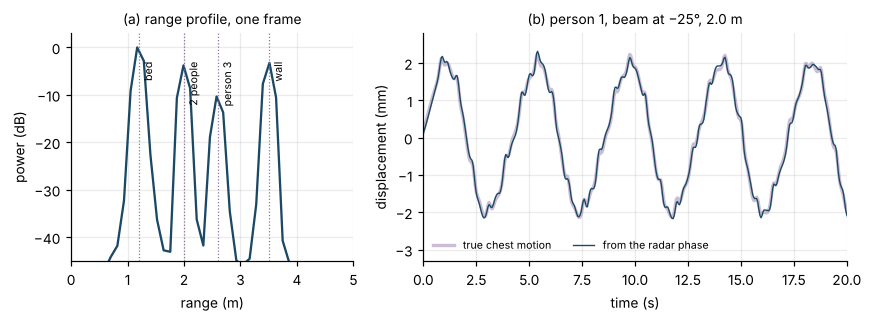

In [5]:
rax = cfg.range_axis()
prof = 20 * np.log10(np.abs(rp[0]).mean(axis=(0, 1)) + 1e-9)
rb = int(round(2.0 / cfg.range_resolution))
z = rp[:, :, :, rb].mean(axis=2) @ (steering(pos, -25.0)[:, 0].conj() / 12)
centre, _ = vitals.circle_fit(z)
d = vitals.displacement(z, cfg.wavelength, centre)
t = truth["t"]

fig, ax = plt.subplots(1, 2, figsize=(8, 3.0), gridspec_kw={"width_ratios": [1, 1.5]})
ax[0].plot(rax, prof - prof.max())
for r0, lab in [(1.2, "bed"), (2.0, "2 people"), (2.6, "person 3"), (3.5, "wall")]:
    ax[0].axvline(r0, color="#8c6d9f", lw=0.8, ls=":")
    ax[0].text(r0 + 0.05, -3, lab, fontsize=7, rotation=90, va="top")
ax[0].set(xlim=(0, 5), ylim=(-45, 3), xlabel="range (m)", ylabel="power (dB)", title="(a) range profile, one frame")
true = truth["displacement"][0]
ax[1].plot(t, 1e3 * (true - true.mean()), color="#8c6d9f", lw=2.2, alpha=0.45, label="true chest motion")
ax[1].plot(t, 1e3 * d, lw=0.9, label="from the radar phase")
ax[1].set(xlim=(0, 20), xlabel="time (s)", ylabel="displacement (mm)", title="(b) person 1, beam at −25°, 2.0 m")
ax[1].legend(loc="lower left", ncol=2, fontsize=7)
ax[1].set_ylim(-3.3, 2.8)
plt.tight_layout()